# Face Mask Classification Using Deep Learning

**Objective:** To detect whether a person is wearing a face mask using a CNN model.

**Technologies:** Python, TensorFlow, CNN, Google Colab, Gradio.

**Output:** With Mask / Without Mask.

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

print("All libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)

All libraries imported successfully!
TensorFlow Version: 2.21.0


In [ ]:
!pip -q install kagglehub

import kagglehub

dataset_path = kagglehub.dataset_download(
    "omkargurav/face-mask-dataset"
)

print("Dataset downloaded successfully!")
print("Dataset path:", dataset_path)

Using Colab cache for faster access to the 'face-mask-dataset' dataset.
Dataset downloaded successfully!
Dataset path: /kaggle/input/face-mask-dataset


In [ ]:
import os

for root, dirs, files in os.walk(dataset_path):
    if "with_mask" in dirs and "without_mask" in dirs:
        dataset_dir = root
        break

print("Dataset Path:", dataset_dir)
print("With Mask:", len(os.listdir(os.path.join(dataset_dir, "with_mask"))))
print("Without Mask:", len(os.listdir(os.path.join(dataset_dir, "without_mask"))))

Dataset Path: /kaggle/input/face-mask-dataset/data
With Mask: 3725
Without Mask: 3828


In [ ]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="training",
    seed=42,
    class_names=["with_mask", "without_mask"]
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="validation",
    seed=42,
    class_names=["with_mask", "without_mask"]
)

train_ds = train_ds.map(
    lambda x, y: (x / 255.0, y)
).prefetch(tf.data.AUTOTUNE)

val_ds = val_ds.map(
    lambda x, y: (x / 255.0, y)
).prefetch(tf.data.AUTOTUNE)

print("Image preprocessing completed!")

Found 7553 files belonging to 2 classes.
Using 6043 files for training.
Found 7553 files belonging to 2 classes.
Using 1510 files for validation.
Image preprocessing completed!


In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(2, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,392,578 (28.20 MB)

 Trainable params: 7,392,578 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[early_stop]
)

Epoch 1/5
189/189 ━━━━━━━━━━━━━━━━━━━━ 163s 852ms/step - accuracy: 0.8066 - loss: 0.5298 - val_accuracy: 0.9007 - val_loss: 0.2425
Epoch 2/5
189/189 ━━━━━━━━━━━━━━━━━━━━ 162s 858ms/step - accuracy: 0.8908 - loss: 0.2737 - val_accuracy: 0.9026 - val_loss: 0.2165
Epoch 3/5
189/189 ━━━━━━━━━━━━━━━━━━━━ 164s 866ms/step - accuracy: 0.9068 - loss: 0.2279 - val_accuracy: 0.9219 - val_loss: 0.1928
Epoch 4/5
189/189 ━━━━━━━━━━━━━━━━━━━━ 160s 844ms/step - accuracy: 0.9250 - loss: 0.1804 - val_accuracy: 0.9272 - val_loss: 0.1815
Epoch 5/5
189/189 ━━━━━━━━━━━━━━━━━━━━ 160s 847ms/step - accuracy: 0.9365 - loss: 0.1634 - val_accuracy: 0.9344 - val_loss: 0.1652


In [ ]:

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1)
])

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)),
    data_augmentation,

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),

    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(2, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,898 (12.61 MB)

 Trainable params: 3,304,898 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
)

Epoch 1/5
189/189 ━━━━━━━━━━━━━━━━━━━━ 218s 1s/step - accuracy: 0.9126 - loss: 0.2263 - val_accuracy: 0.9238 - val_loss: 0.1892
Epoch 2/5
189/189 ━━━━━━━━━━━━━━━━━━━━ 224s 1s/step - accuracy: 0.9133 - loss: 0.2159 - val_accuracy: 0.9344 - val_loss: 0.1743
Epoch 3/5
189/189 ━━━━━━━━━━━━━━━━━━━━ 219s 1s/step - accuracy: 0.9257 - loss: 0.1967 - val_accuracy: 0.9371 - val_loss: 0.1574
Epoch 4/5
189/189 ━━━━━━━━━━━━━━━━━━━━ 228s 1s/step - accuracy: 0.9335 - loss: 0.1689 - val_accuracy: 0.9530 - val_loss: 0.1259
Epoch 5/5
189/189 ━━━━━━━━━━━━━━━━━━━━ 263s 1s/step - accuracy: 0.9422 - loss: 0.1583 - val_accuracy: 0.9517 - val_loss: 0.1272


48/48 ━━━━━━━━━━━━━━━━━━━━ 14s 287ms/step - accuracy: 0.9517 - loss: 0.1272
Validation Accuracy: 95.17 %
Validation Loss: 0.1272


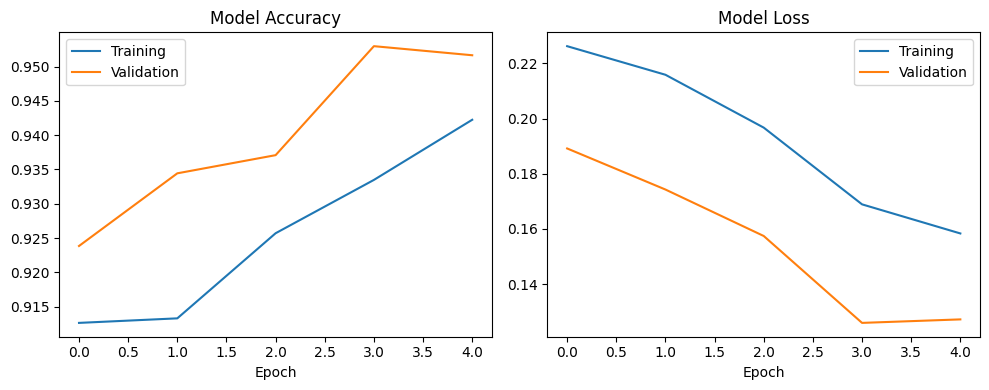

In [ ]:
loss, accuracy = model.evaluate(val_ds)

print("Validation Accuracy:", round(accuracy * 100, 2), "%")
print("Validation Loss:", round(loss, 4))

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
def predict_mask(image):
    image = image.convert("RGB")
    image = image.resize((128, 128))

    img_array = np.array(image, dtype=np.float32) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array, verbose=0)[0]

    return {
        "With Mask": float(prediction[0]),
        "Without Mask": float(prediction[1])
    }

In [26]:
!pip -q install gradio

import gradio as gr
from PIL import Image
import numpy as np

labels = ["With Mask", "Without Mask"]

def predict_mask(image):
    image = image.convert("RGB").resize((128, 128))

    img = np.array(image, dtype=np.float32) / 255.0
    img = np.expand_dims(img, axis=0)

    prediction = model.predict(img, verbose=0)[0]

    return {
        labels[i]: float(prediction[i])
        for i in range(2)
    }

demo = gr.Interface(
    fn=predict_mask,
    inputs=gr.Image(type="pil", label="Upload Face Image"),
    outputs=gr.Label(num_top_classes=2),
    title="Face Mask Using CNN",
    description="Upload an image to predict mask status."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4b0ad1a53b049c8317.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
#new cell

In [ ]:
# We can define the classes directly, as .map() and .prefetch() strip custom attributes like .class_names
class_names = ["with_mask", "without_mask"]

print("Class names:", class_names)
print("Model output shape:", model.output_shape)

Class names: ['with_mask', 'without_mask']
Model output shape: (None, 2)


In [ ]:
model.save("face_mask_cnn.keras")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
from google.colab import files

files.download("face_mask_cnn.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion

The Face Mask Detection project was developed using Deep Learning and a Convolutional Neural Network (CNN). The model classifies uploaded images into With Mask and Without Mask categories. An interactive interface was created using Gradio to display predictions. This project helped me understand image preprocessing, CNN model training, model evaluation, and image classification.